# Email Spam Detection Using Machine Learning

## 1. Introduction
Email and SMS spam messages are unwanted messages that may contain advertisements, misleading information, or fraudulent links. Detecting spam automatically helps improve communication security.

## 2. Objective
The objective of this project is to develop a machine learning model that classifies text messages as Spam or Ham (Not Spam).

## 3. Dataset Description
The SMS Spam Collection dataset contains labeled messages categorized as spam or ham.

## 4. Algorithms Used
- Multinomial Naive Bayes
- Logistic Regression

## 5. Techniques Used
- Text preprocessing
- Natural Language Processing (NLP)
- TF-IDF Vectorization
- Machine Learning Classification

## 6. Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [26]:
from pathlib import Path

file_path = Path("spam.csv")

print("File exists:", file_path.exists())

with open(file_path, "r", encoding="latin-1") as file:
    for i in range(5):
        print(file.readline())


File exists: True
ham	Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

ham	Ok lar... Joking wif u oni...

spam	Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

ham	U dun say so early hor... U c already then say...

ham	Nah I don't think he goes to usf, he lives around here though



In [27]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current working directory:
c:\Users\kumar\OneDrive\Desktop\OIBSIP\DataScience-Task4-EmailSpamDetection

Files in this folder:
['Harikaa_Task4.ipynb', 'Harika_Task4.ipynb', 'spam.csv']


In [28]:
with open("spam.csv", "r", encoding="latin-1") as file:
    for i in range(10):
        line = file.readline()
        print(f"Line {i+1}: {repr(line)}")

Line 1: 'ham\tGo until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...\n'
Line 2: 'ham\tOk lar... Joking wif u oni...\n'
Line 3: "spam\tFree entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's\n"
Line 4: 'ham\tU dun say so early hor... U c already then say...\n'
Line 5: "ham\tNah I don't think he goes to usf, he lives around here though\n"
Line 6: "spam\tFreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, Â£1.50 to rcv\n"
Line 7: 'ham\tEven my brother is not like to speak with me. They treat me like aids patent.\n'
Line 8: "ham\tAs per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune\n"
Line 9: 'spam\tWINNER!! As a valued network customer you have be

In [29]:
import sys

print("Python executable:")
print(sys.executable)

Python executable:
c:\Users\kumar\OneDrive\Desktop\OIBSIP\DataScience-Task1-IrisFlowerClassification\.venv\Scripts\python.exe


In [30]:
import pandas as pd

# Load the SMS Spam Collection dataset

df = pd.read_csv(
    "spam.csv",
    sep="\t",
    header=None,
    names=["Category", "Message"],
    encoding="latin-1"
)

print("Dataset loaded successfully!")

print("\nDataset Shape:", df.shape)

print("\nFirst 5 messages:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset loaded successfully!

Dataset Shape: (5572, 2)

First 5 messages:


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Column Names:
['Category', 'Message']


In [31]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nCategory Distribution:")
print(df["Category"].value_counts())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Category  5572 non-null   str  
 1   Message   5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB

Missing Values:
Category    0
Message     0
dtype: int64

Duplicate Rows:
403

Category Distribution:
Category
ham     4825
spam     747
Name: count, dtype: int64

Statistical Summary:


,Category,Message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


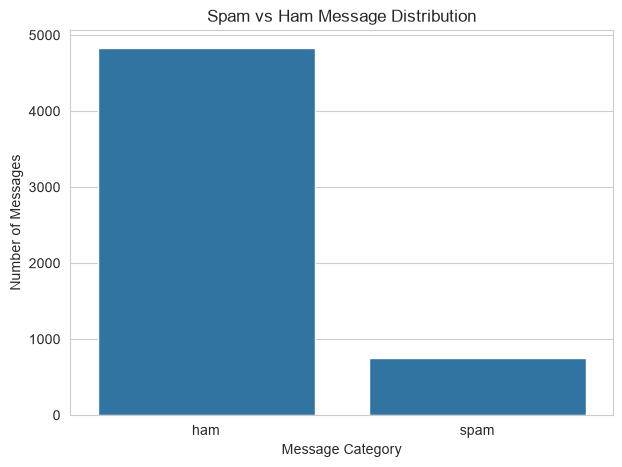

In [32]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Category")

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

In [33]:
# Remove missing values

df = df.dropna()

# Remove duplicate messages

df = df.drop_duplicates()

# Reset index

df = df.reset_index(drop=True)

print("Dataset cleaned successfully!")

Dataset cleaned successfully!


In [34]:
# Keep only the required columns

df.columns = ["v1", "v2"]

# Rename columns

df.columns = ["Category", "Message"]

print("Dataset loaded successfully!")

display(df.head())

print("\nDataset Shape:", df.shape)

Dataset loaded successfully!


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Dataset Shape: (5169, 2)


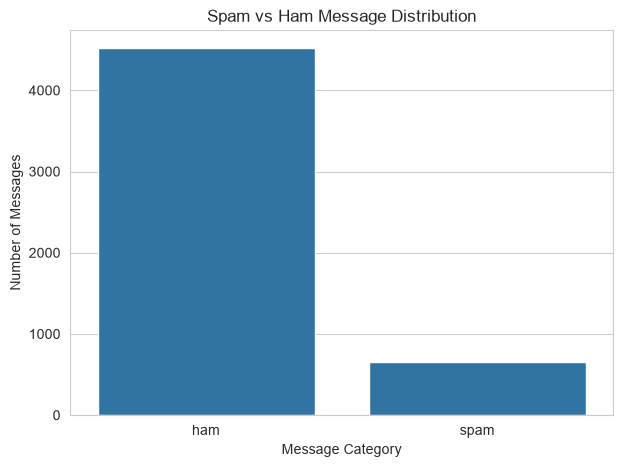

In [35]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Category"
)

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

In [36]:
# Remove missing values

df = df.dropna()

# Remove duplicate messages

df = df.drop_duplicates()

# Reset index

df = df.reset_index(drop=True)

print("Dataset cleaned successfully!")

print("\nCleaned Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset cleaned successfully!

Cleaned Dataset Shape: (5169, 2)

Missing Values:
Category    0
Message     0
dtype: int64

Duplicate Rows: 0


In [37]:
df["Category"] = df["Category"].map({
    "ham": 0,
    "spam": 1
})

print("Category conversion completed!")

print(df["Category"].value_counts())
display(df.head())

Category conversion completed!
Category
0    4516
1     653
Name: count, dtype: int64


,Category,Message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [38]:
def clean_text(text):
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["Cleaned_Message"] = df["Message"].apply(clean_text)

display(df[["Message", "Cleaned_Message"]].head(10))

,Message,Cleaned_Message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling its been weeks now a...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,Had your mobile 11 months or more? U R entitle...,had your mobile months or more u r entitled to...


In [39]:
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X = tfidf.fit_transform(df["Cleaned_Message"])

y = df["Category"]

print("TF-IDF conversion completed!")
print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

TF-IDF conversion completed!
Feature Matrix Shape: (5169, 5000)
Target Shape: (5169,)


In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining completed for data preparation!")

Training data shape: (4135, 5000)
Testing data shape: (1034, 5000)

Training completed for data preparation!


In [41]:
nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

nb_predictions = nb_model.predict(X_test)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [42]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [43]:
print(y_train.unique())
print(y_test.unique())

[0 1]
[0 1]


In [44]:
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1 Score": f1_score(actual, predicted, zero_division=0)
    }

results = pd.DataFrame([
    evaluate_model("Naive Bayes", y_test, nb_predictions),
    evaluate_model("Logistic Regression", y_test, lr_predictions)
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.9720,1.0000,0.7786,0.8755
1,Logistic Regression,0.9449,0.9868,0.5725,0.7246


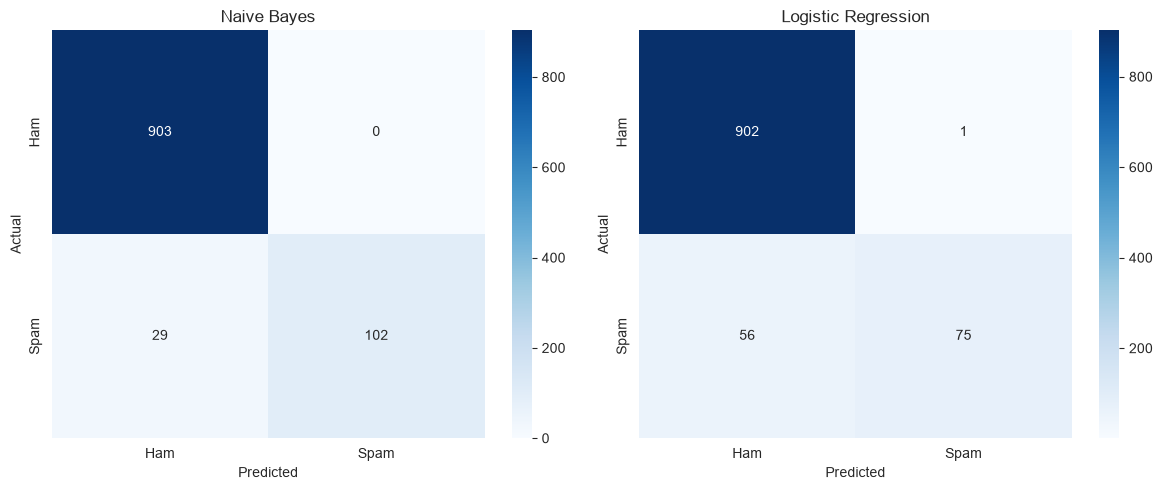

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Naive Bayes", nb_predictions),
    ("Logistic Regression", lr_predictions)
]

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [46]:
print("NAIVE BAYES CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=["Ham", "Spam"]
))

print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Ham", "Spam"]
))

NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       1.00      0.78      0.88       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.94      1.00      0.97       903
        Spam       0.99      0.57      0.72       131

    accuracy                           0.94      1034
   macro avg       0.96      0.79      0.85      1034
weighted avg       0.95      0.94      0.94      1034



In [47]:
def predict_message(message):
    cleaned = clean_text(message)
    transformed = tfidf.transform([cleaned])

    prediction = lr_model.predict(transformed)[0]

    if prediction == 1:
        print("Result: SPAM MESSAGE")
    else:
        print("Result: HAM (NOT SPAM)")


predict_message("Congratulations! You won a free prize. Click here now!")

predict_message("Hey, are we meeting for lunch today?")

Result: SPAM MESSAGE
Result: HAM (NOT SPAM)


## Conclusion

The Email Spam Detection project uses Natural Language Processing
and Machine Learning to classify text messages as spam or ham.

Text preprocessing and TF-IDF vectorization were used to convert
messages into numerical features.

Two machine learning algorithms, Multinomial Naive Bayes and
Logistic Regression, were trained and evaluated.

The models were compared using accuracy, precision, recall,
F1-score, and confusion matrices.

The better-performing model was selected for predicting whether
new messages are spam or genuine.

This project demonstrates the application of machine learning
and NLP in automated spam message detection.